# China GDP Prediction

**Author:** Farid Shafi

**GitHub:** [Farid-Dev-13](https://github.com/Farid-Dev-13)

**Project:** China GDP Prediction

**Date:** November 2026

## Project Overview

The goal of this project is to explore China's historical GDP data and model the relationship between Year and GDP.

In this project, I implement and compare different regression techniques to see how well they fit the historical data.

The models include Linear Regression, Polynomial Regression, Exponential Regression, and Sigmoid Regression.

Model performance is evaluated using R² Score and Mean Absolute Error (MAE).

## Dataset Source

The dataset used in this project is `china_gdp.csv`.

It was obtained from Jadi's Machine Learning with Python course.

**Course:** [Machine Learning with Python – Maktabkhooneh](https://maktabkhooneh.org/course/%DB%8C%D8%A7%D8%AF%DA%AF%DB%8C%D8%B1%DB%8C-%D9%85%D8%A7%D8%B4%DB%8C%D9%86-%D9%BE%D8%A7%DB%8C%D8%AA%D9%88%D9%86-mk1318/)

**GitHub Repository:** [Jadi's GitHub](https://github.com/jadijadi/machine_learning_with_python_jadi)

**Dataset:** [china_gdp.csv](https://github.com/jadijadi/machine_learning_with_python_jadi/blob/main/china_gdp.csv)

## 1. Data Loading and Exploration

First, I load the China GDP dataset and explore its structure, dimensions, data types, and missing values.

I also visualize the relationship between Year and GDP to understand the overall growth trend.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_absolute_error

from scipy.optimize import curve_fit

In [2]:
df = pd.read_csv('china_gdp.csv')

df.head()

,Year,Value
0,1960,5.918412e+10
1,1961,4.955705e+10
2,1962,4.668518e+10
3,1963,5.009730e+10
4,1964,5.906225e+10


In [3]:
print('Shape:', df.shape)

print('\nData Types:')
print(df.dtypes)

print('\nMissing Values:')
print(df.isnull().sum())


Shape: (55, 2)

Data Types:
Year       int64
Value    float64
dtype: object

Missing Values:
Year     0
Value    0
dtype: int64


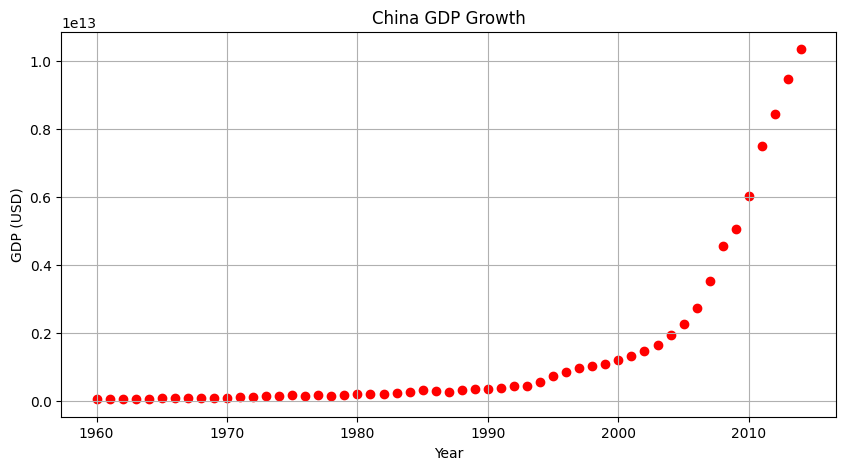

In [4]:
plt.figure(figsize=(10, 5))

plt.scatter(df['Year'], df['Value'], color='red')

plt.title('China GDP Growth')
plt.xlabel('Year')
plt.ylabel('GDP (USD)')

plt.grid(True)
plt.show()

## 2. Data Preparation

I select Year as the independent variable (X) and Value as the dependent variable (y).

Then, I split the dataset into training and testing sets.

The same train-test split is used for all models to keep the comparison consistent.

In [5]:
x = df[['Year']]
y = df[['Value']]

In [6]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

## 3. Linear Regression

Linear Regression is used as the baseline model.

It attempts to find a straight-line relationship between Year and GDP.

In [7]:
linear_model = LinearRegression()

linear_model.fit(x_train, y_train)

print('Coefficient:', linear_model.coef_)
print('Intercept:', linear_model.intercept_)

Coefficient: [[1.09727972e+11]]
Intercept: [-2.1657979e+14]


In [8]:
linear_train_pred = linear_model.predict(x_train)
linear_test_pred = linear_model.predict(x_test)

In [9]:
linear_train_r2 = r2_score(y_train, linear_train_pred)
linear_test_r2 = r2_score(y_test, linear_test_pred)

linear_mae = mean_absolute_error(y_test, linear_test_pred)

print('Train R2:', linear_train_r2)
print('Test R2:', linear_test_r2)
print('MAE:', linear_mae)

Train R2: 0.5130560991038982
Test R2: 0.557799840215933
MAE: 1341446144991.7834


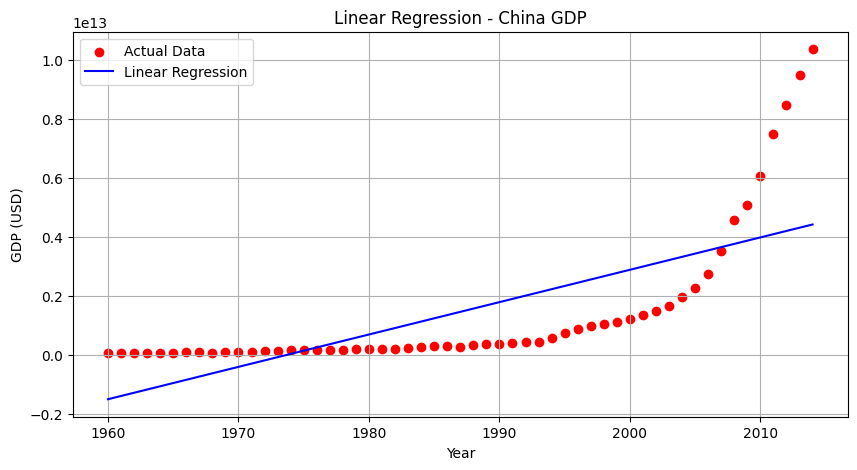

In [10]:
plt.figure(figsize=(10, 5))

plt.scatter(df['Year'], df['Value'], color='red', label='Actual Data')

plt.plot(
    x,
    linear_model.predict(x),
    color='blue',
    label='Linear Regression'
)

plt.title('Linear Regression - China GDP')
plt.xlabel('Year')
plt.ylabel('GDP (USD)')

plt.legend()
plt.grid(True)
plt.show()

## 4. Polynomial Regression

Polynomial Regression extends Linear Regression by adding polynomial features.

This allows the model to capture nonlinear relationships between Year and GDP.

I experiment with degrees from 2 to 5 to investigate how increasing model complexity affects prediction performance.

In [11]:
polynomial_models = {}
polynomial_results = {}

for degree in range(2, 6):

    poly = PolynomialFeatures(degree=degree)

    x_train_poly = poly.fit_transform(x_train)
    x_test_poly = poly.transform(x_test)

    model = LinearRegression()

    model.fit(x_train_poly, y_train)

    train_pred = model.predict(x_train_poly)
    test_pred = model.predict(x_test_poly)

    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)
    mae = mean_absolute_error(y_test, test_pred)

    polynomial_models[degree] = (poly, model)

    polynomial_results[degree] = {
        'Train R2': train_r2,
        'Test R2': test_r2,
        'MAE': mae
    }

    print(f'\nPolynomial Degree {degree}')
    print('Train R2:', train_r2)
    print('Test R2:', test_r2)
    print('MAE:', mae)


Polynomial Degree 2
Train R2: 0.5159972511879322
Test R2: 0.5606702825773766
MAE: 1338191862499.6272

Polynomial Degree 3
Train R2: 0.8383393062062527
Test R2: 0.8632341078219203
MAE: 745978073037.7667

Polynomial Degree 4
Train R2: 0.8402151943937262
Test R2: 0.8648696813145258
MAE: 741397689560.494

Polynomial Degree 5
Train R2: 0.842078855511381
Test R2: 0.8664919536496081
MAE: 736797929588.7212


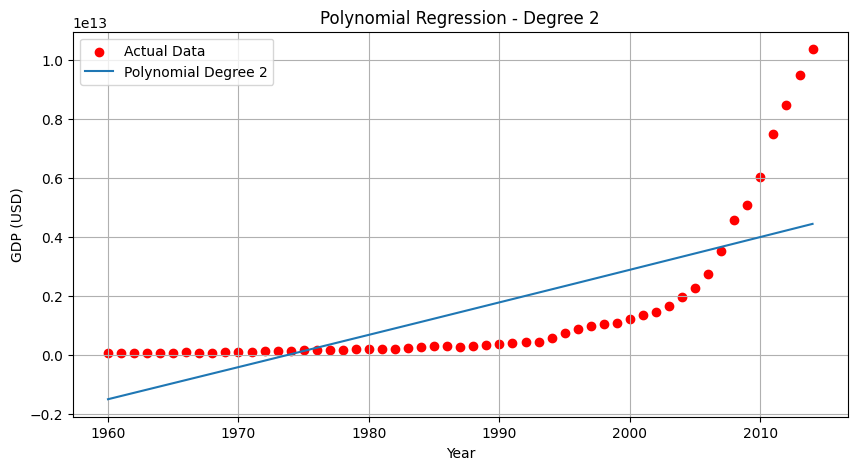

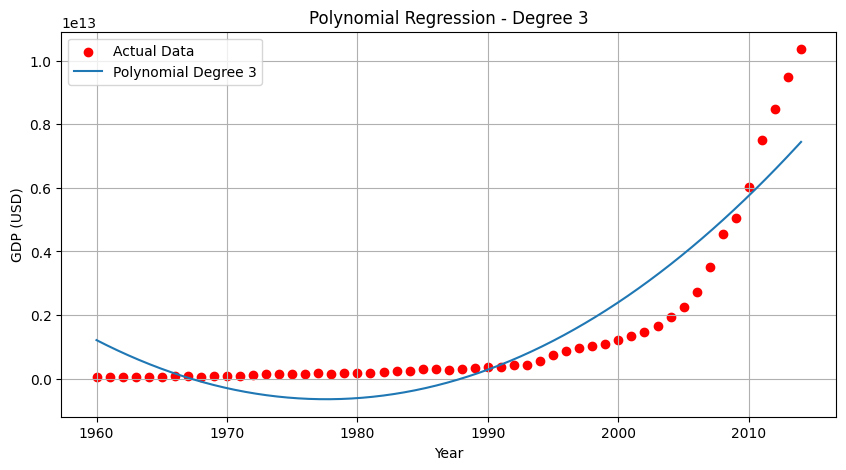

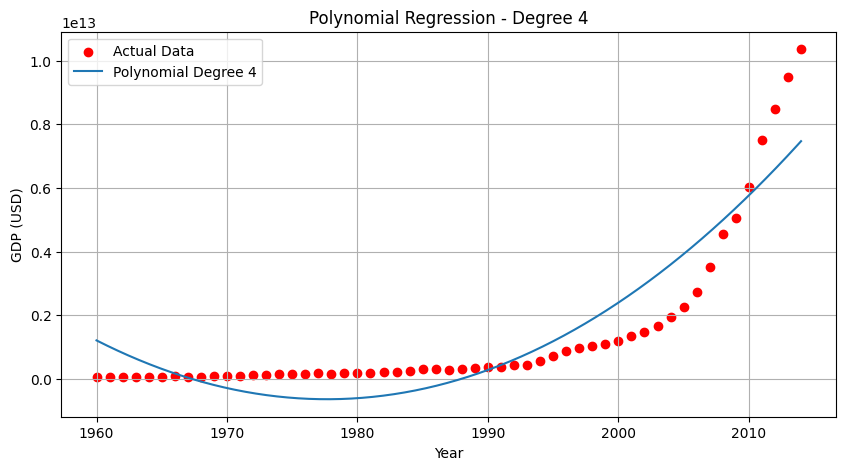

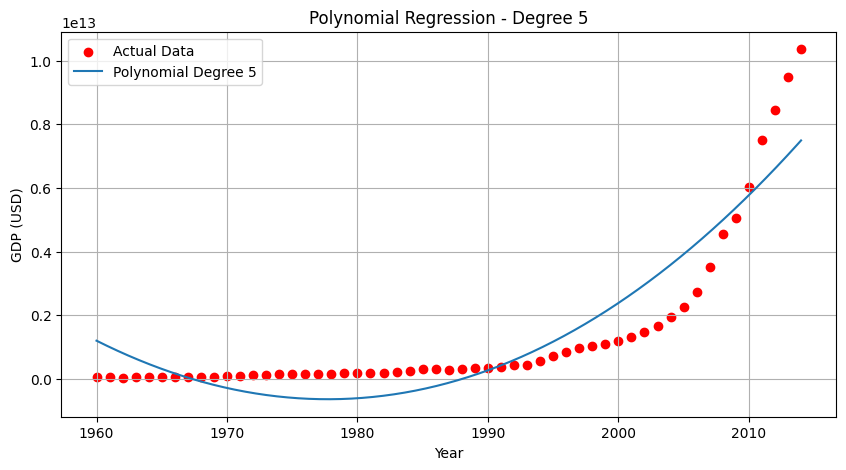

In [12]:
x_plot = pd.DataFrame({
    'Year': np.linspace(
    df['Year'].min(),
    df['Year'].max(),
    200
)
})

for degree, (poly, model) in polynomial_models.items():

    x_plot_poly = poly.transform(x_plot)
    y_plot = model.predict(x_plot_poly)

    plt.figure(figsize=(10, 5))

    plt.scatter(
        df['Year'],
        df['Value'],
        color='red',
        label='Actual Data'
    )

    plt.plot(
        x_plot,
        y_plot,
        label=f'Polynomial Degree {degree}'
    )

    plt.title(f'Polynomial Regression - Degree {degree}')
    plt.xlabel('Year')
    plt.ylabel('GDP (USD)')

    plt.legend()
    plt.grid(True)
    plt.show()

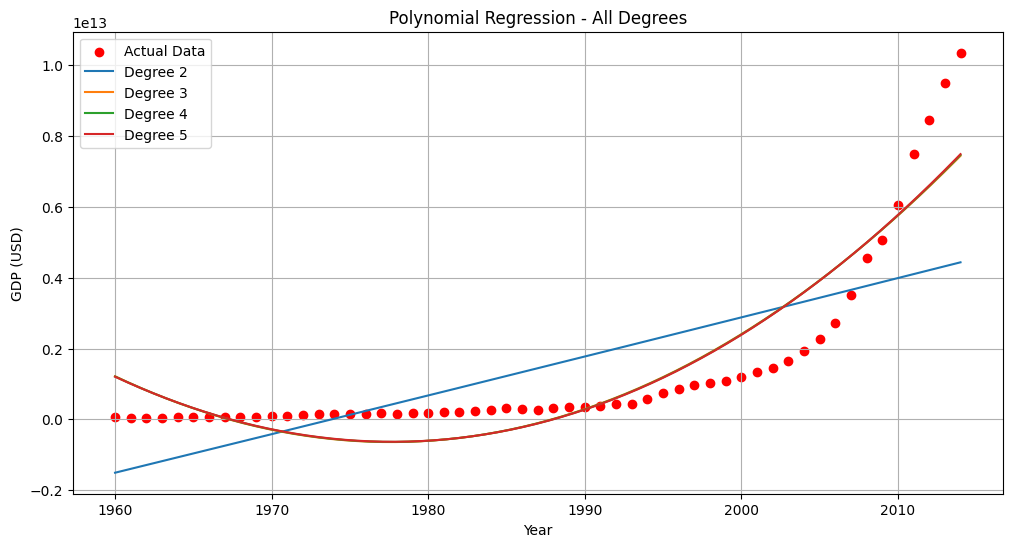

In [13]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df['Year'],
    df['Value'],
    color='red',
    label='Actual Data'
)

for degree, (poly, model) in polynomial_models.items():

    x_plot_poly = poly.transform(x_plot)
    y_plot = model.predict(x_plot_poly)

    plt.plot(
        x_plot,
        y_plot,
        label=f'Degree {degree}'
    )

plt.title('Polynomial Regression - All Degrees')
plt.xlabel('Year')
plt.ylabel('GDP (USD)')

plt.legend()
plt.grid(True)
plt.show()

In [14]:
polynomial_df = pd.DataFrame(polynomial_results).T

polynomial_df.index.name = 'Degree'

polynomial_df

,Train R2,Test R2,MAE
Degree,,,
2,0.515997,0.560670,1.338192e+12
3,0.838339,0.863234,7.459781e+11
4,0.840215,0.864870,7.413977e+11
5,0.842079,0.866492,7.367979e+11


## 5. Nonlinear Regression

In this section, I explore nonlinear regression models to capture the growth pattern of China's GDP.

Unlike Polynomial Regression, these models use predefined mathematical functions to represent the relationship between Year and GDP.

### 5.1 Exponential Regression

Exponential Regression models growth using an exponential function:

y = a × e^(b × x)

Since the Year values are relatively large, I subtract the minimum training year from the input values to make them smaller and improve numerical stability.

The model is fitted using SciPy's `curve_fit` function.

The same training and testing sets used in the previous sections are also used here.

In [15]:
def exponential(x, a, b):
    return a * np.exp(b * x)

In [16]:
x_train_1D = x_train.values.ravel()
x_test_1D = x_test.values.ravel()

y_train_1D = y_train.values.ravel()
y_test_1D = y_test.values.ravel()

year_min = min(x_train_1D)

x_train_scaled = x_train_1D - year_min
x_test_scaled = x_test_1D - year_min

In [17]:
popt_exp, pcov_exp = curve_fit(
    exponential,
    x_train_scaled,
    y_train_1D,
    maxfev=10000
)

a, b = popt_exp

print('a:', a)
print('b:', b)

a: 2695950728.184199
b: 0.153642194297709


In [18]:
exp_train_pred = exponential(x_train_scaled, a, b)
exp_test_pred = exponential(x_test_scaled, a, b)

In [19]:
exp_train_r2 = r2_score(y_train_1D, exp_train_pred)
exp_test_r2 = r2_score(y_test_1D, exp_test_pred)

exp_mae = mean_absolute_error(y_test_1D, exp_test_pred)

print('Train R2:', exp_train_r2)
print('Test R2:', exp_test_r2)
print('MAE:', exp_mae)

Train R2: 0.9931246641992835
Test R2: 0.9934669773715946
MAE: 155632534863.03366


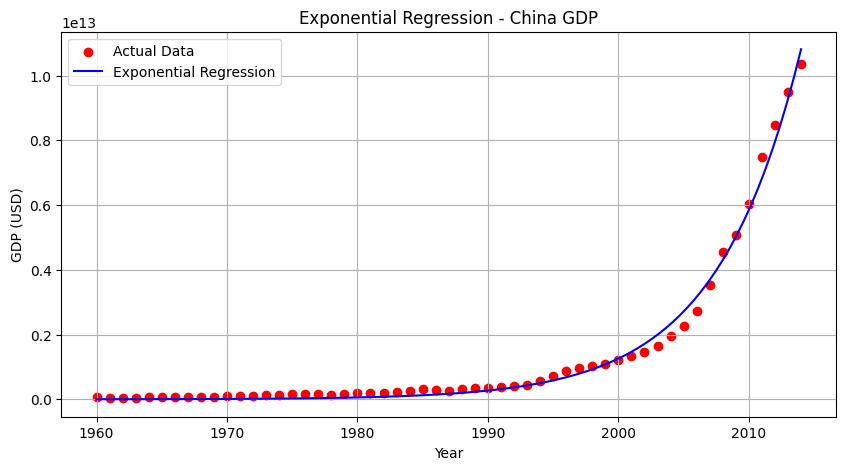

In [20]:
x_plot = np.linspace(
    df['Year'].min(),
    df['Year'].max(),
    100
)

x_plot_scaled = x_plot - year_min

y_plot = exponential(x_plot_scaled, *popt_exp)

plt.figure(figsize=(10, 5))

plt.scatter(
    df['Year'],
    df['Value'],
    color='red',
    label='Actual Data'
)

plt.plot(
    x_plot,
    y_plot,
    color='blue',
    label='Exponential Regression'
)

plt.title('Exponential Regression - China GDP')
plt.xlabel('Year')
plt.ylabel('GDP (USD)')

plt.legend()
plt.grid(True)
plt.show()

### 5.2 Sigmoid Regression

Sigmoid Regression uses a logistic-shaped function to model growth that may eventually slow down and approach an upper limit.

This is a nonlinear regression approach and is different from `LogisticRegression`, which is commonly used for classification.

The function has three parameters:

- L: Upper limit of the curve
- k: Growth rate
- x0: Inflection point

To improve numerical stability, GDP values are divided by 10¹² during model fitting.

Predictions are converted back to the original GDP scale for visualization and evaluation.

In [21]:
def sigmoid(x, L, k, x0):
    return L / (1 + np.exp(-k * (x - x0)))

In [22]:
y_train_scaled = y_train_1D / 1e12
y_test_scaled = y_test_1D / 1e12

In [23]:
popt_sig, pcov_sig = curve_fit(
    sigmoid,
    x_train_scaled,
    y_train_scaled
)

L, k, x0 = popt_sig

print('L:', L)
print('k:', k)
print('x0:', x0)

L: 58.46749799844679
k: 0.1700838073684083
x0: 62.79926529421913


In [24]:
sig_train_pred = sigmoid(x_train_scaled, *popt_sig)
sig_test_pred = sigmoid(x_test_scaled, *popt_sig)

In [25]:
sig_train_r2 = r2_score(y_train_scaled, sig_train_pred)
sig_test_r2 = r2_score(y_test_scaled, sig_test_pred)

sig_mae = mean_absolute_error(
    y_test_1D,
    sig_test_pred * 1e12
)

print('Train R2:', sig_train_r2)
print('Test R2:', sig_test_r2)
print('MAE:', sig_mae)

Train R2: 0.9934355100825235
Test R2: 0.9945938938813734
MAE: 154318361591.7966


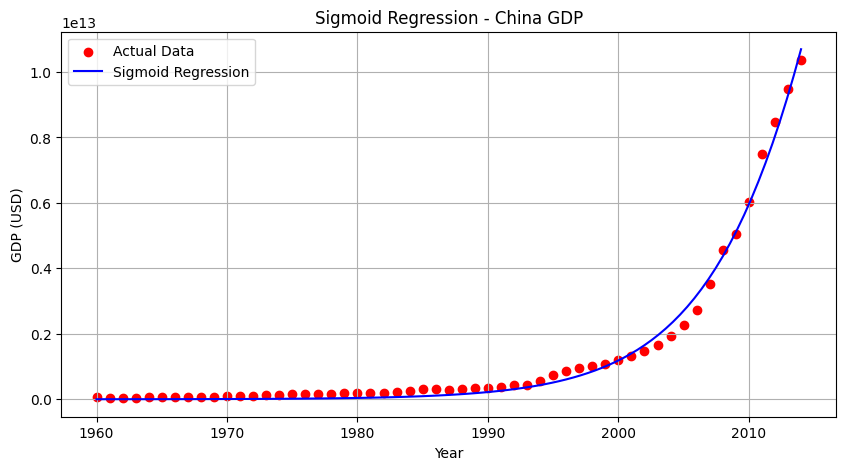

In [26]:
x_plot = np.linspace(
    df['Year'].min(),
    df['Year'].max(),
    100
)

x_plot_scaled = x_plot - year_min

y_plot = sigmoid(x_plot_scaled, *popt_sig) * 1e12

plt.figure(figsize=(10, 5))

plt.scatter(
    df['Year'],
    df['Value'],
    color='red',
    label='Actual Data'
)

plt.plot(
    x_plot,
    y_plot,
    color='blue',
    label='Sigmoid Regression'
)

plt.title('Sigmoid Regression - China GDP')
plt.xlabel('Year')
plt.ylabel('GDP (USD)')

plt.legend()
plt.grid(True)
plt.show()

## 6. Model Comparison

In this section, I compare all seven model configurations using:

- Train R² Score
- Test R² Score
- Mean Absolute Error (MAE)

R² Score measures how well a model explains the variation in the target values. MAE measures the average absolute difference between actual and predicted values.

All models use the same train-test split. MAE is calculated on the original GDP scale so that the results can be compared directly.

In [27]:
results = {
    'Model': [
        'Linear Regression',
        'Polynomial Degree 2',
        'Polynomial Degree 3',
        'Polynomial Degree 4',
        'Polynomial Degree 5',
        'Exponential Regression',
        'Sigmoid Regression'
    ],

    'Train R2': [
        linear_train_r2,
        *[polynomial_results[d]['Train R2'] for d in range(2, 6)],
        exp_train_r2,
        sig_train_r2
    ],

    'Test R2': [
        linear_test_r2,
        *[polynomial_results[d]['Test R2'] for d in range(2, 6)],
        exp_test_r2,
        sig_test_r2
    ],

    'MAE': [
        linear_mae,
        *[polynomial_results[d]['MAE'] for d in range(2, 6)],
        exp_mae,
        sig_mae
    ]
}

result_df = pd.DataFrame(results)

result_df

,Model,Train R2,Test R2,MAE
0,Linear Regression,0.513056,0.557800,1.341446e+12
1,Polynomial Degree 2,0.515997,0.560670,1.338192e+12
2,Polynomial Degree 3,0.838339,0.863234,7.459781e+11
3,Polynomial Degree 4,0.840215,0.864870,7.413977e+11
4,Polynomial Degree 5,0.842079,0.866492,7.367979e+11
5,Exponential Regression,0.993125,0.993467,1.556325e+11
6,Sigmoid Regression,0.993436,0.994594,1.543184e+11


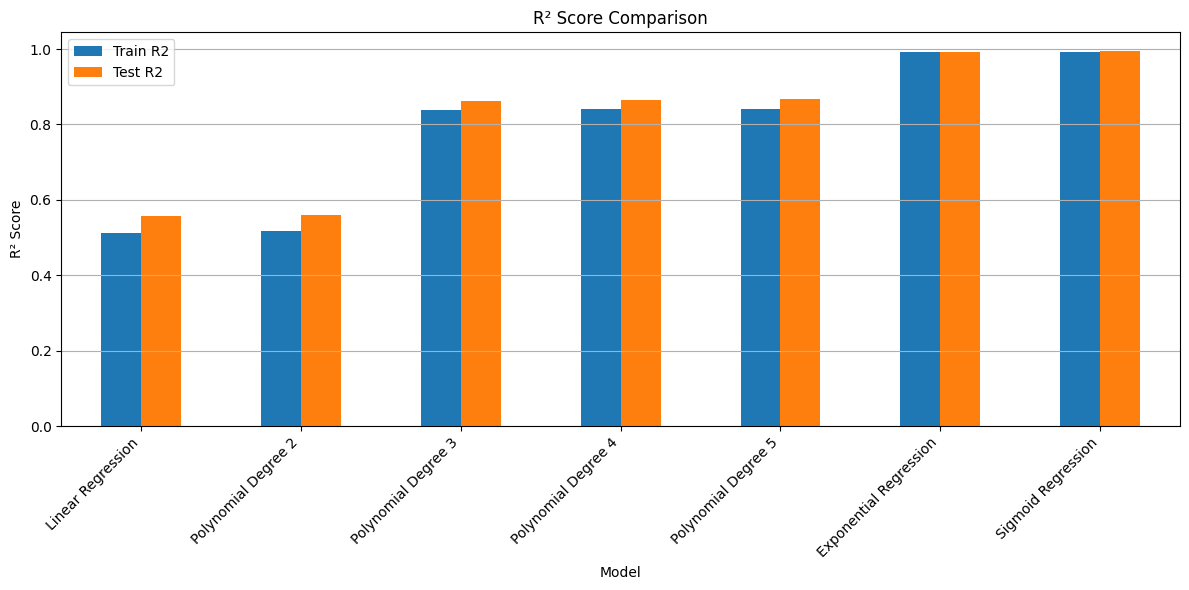

In [28]:
result_df.plot(
    x='Model',
    y=['Train R2', 'Test R2'],
    kind='bar',
    figsize=(12, 6)
)

plt.title('R² Score Comparison')
plt.xlabel('Model')
plt.ylabel('R² Score')

plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

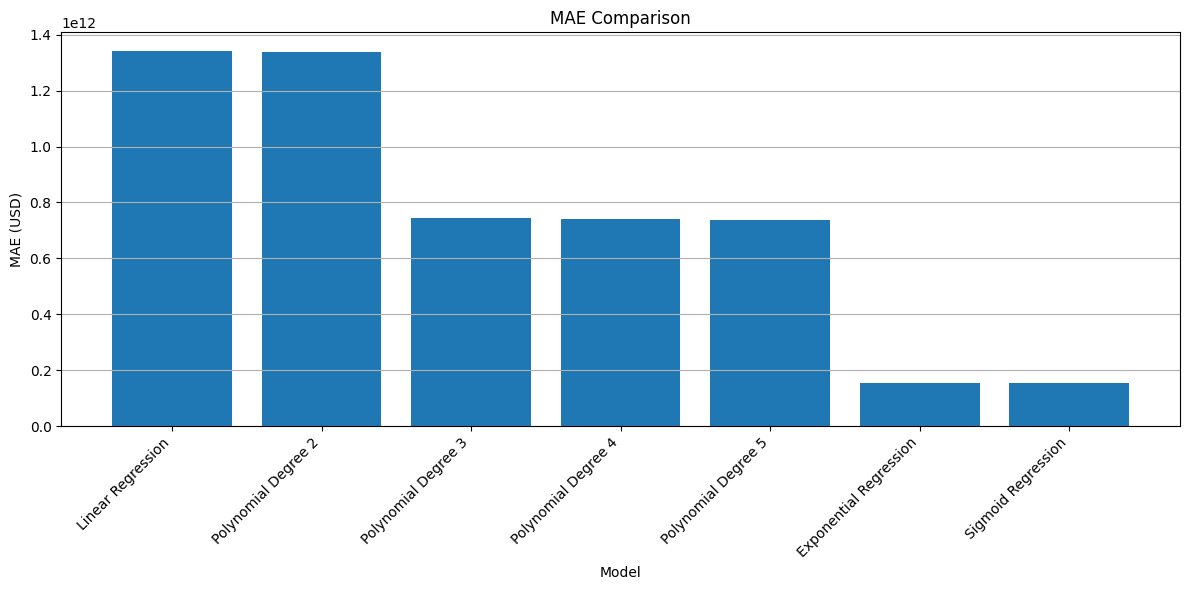

In [29]:
plt.figure(figsize=(12, 6))

plt.bar(
    result_df['Model'],
    result_df['MAE']
)

plt.title('MAE Comparison')
plt.xlabel('Model')
plt.ylabel('MAE (USD)')

plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [30]:
best_model = result_df.loc[result_df['Test R2'].idxmax()]

print('Best Model:')
print(best_model)

Best Model:
Model       Sigmoid Regression
Train R2              0.993436
Test R2               0.994594
MAE          154318361591.7966
Name: 6, dtype: object


## 7. Residual Analysis

Residuals represent the difference between actual values and predicted values.

In this section, I check the residuals of different models to understand how far their predictions are from the actual GDP values.

A good model should have residuals distributed around zero.

In [31]:
test_predictions = {
    'Linear Regression': linear_test_pred.ravel()
}

for degree, (poly, model) in polynomial_models.items():

    x_test_poly = poly.transform(x_test)

    test_predictions[f'Polynomial Degree {degree}'] = (
        model.predict(x_test_poly).ravel()
    )

test_predictions['Exponential Regression'] = exp_test_pred

test_predictions['Sigmoid Regression'] = sig_test_pred * 1e12

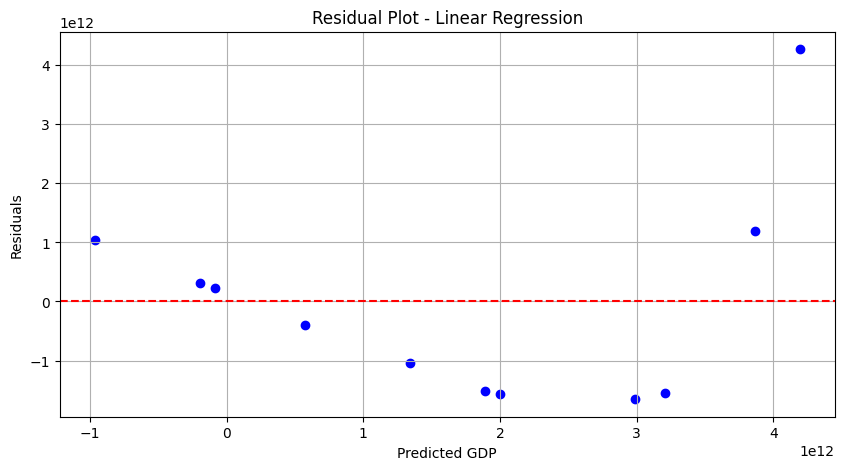

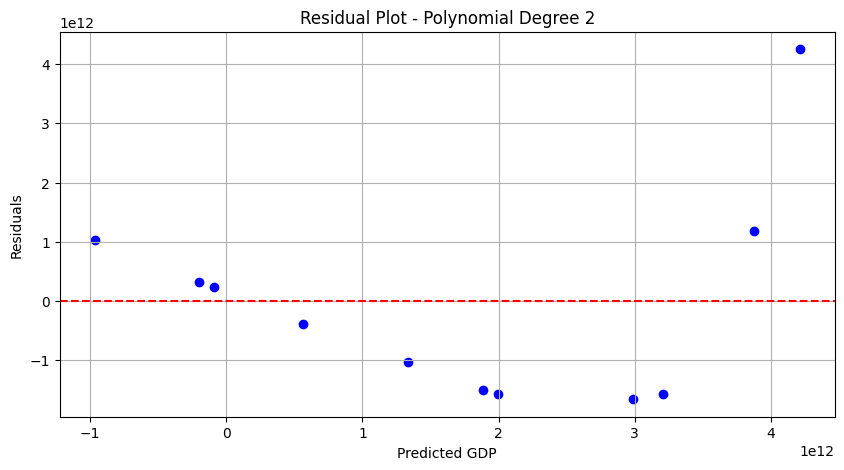

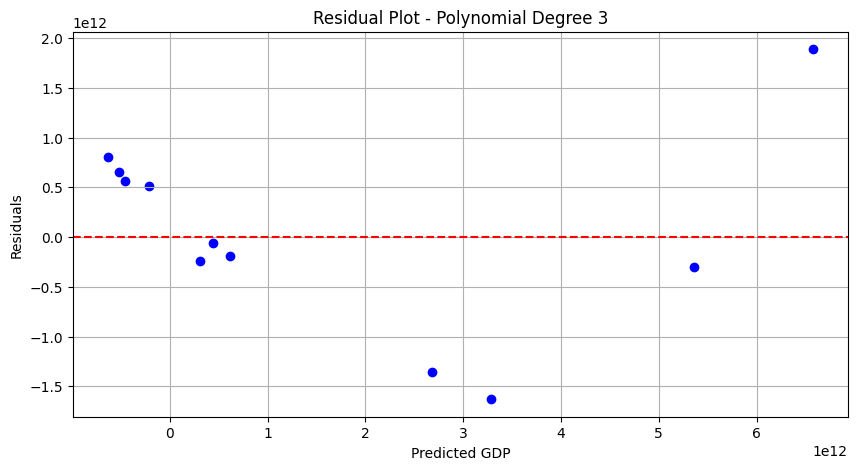

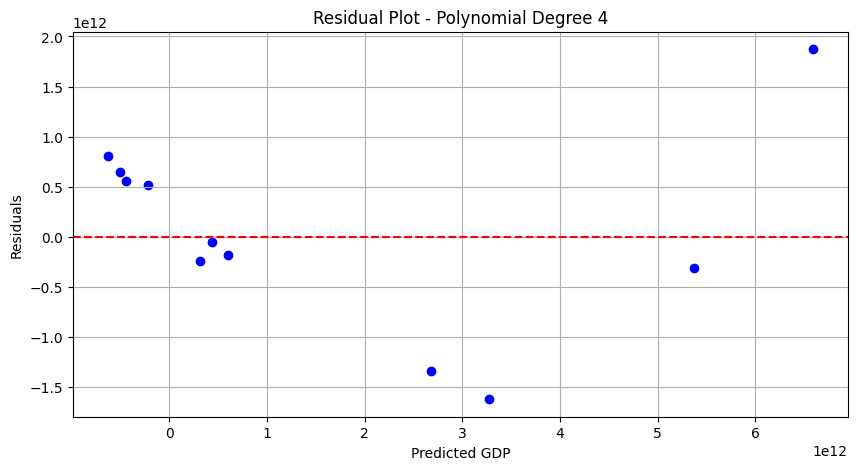

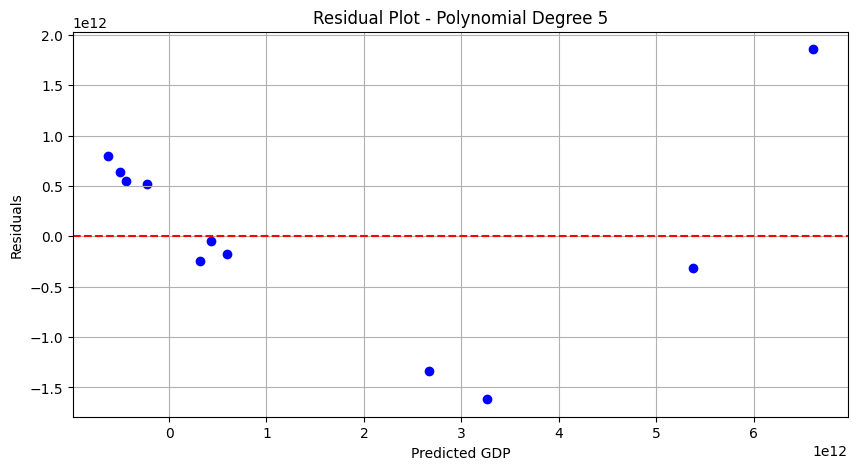

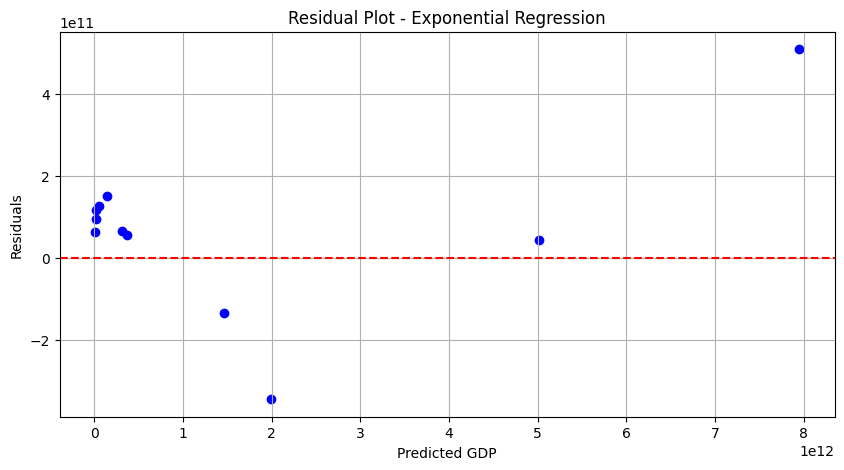

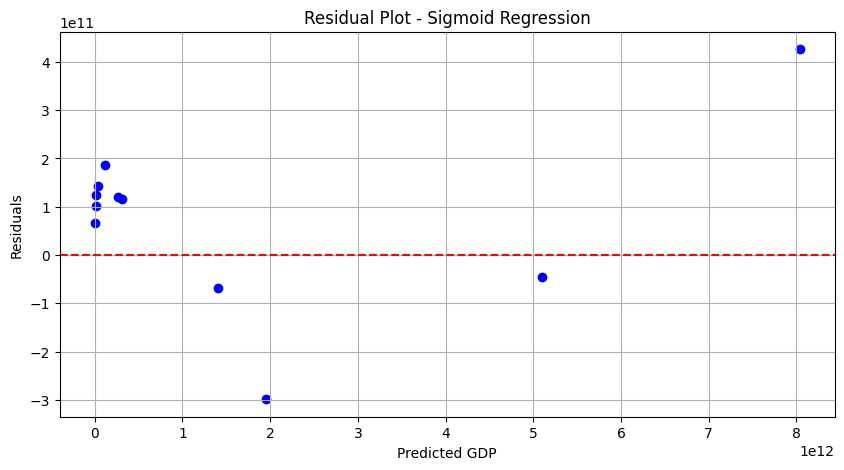

In [32]:
for name, predictions in test_predictions.items():

    residuals = y_test_1D - predictions

    plt.figure(figsize=(10, 5))

    plt.scatter(
        predictions,
        residuals,
        color='blue'
    )

    plt.axhline(
        y=0,
        color='red',
        linestyle='--'
    )

    plt.title(f'Residual Plot - {name}')
    plt.xlabel('Predicted GDP')
    plt.ylabel('Residuals')

    plt.grid(True)
    plt.show()

## 8. Model Interpretation

After comparing the models, I observed some differences in their performance.

- Linear Regression could not fully capture the growth pattern in the dataset.
- Polynomial Regression provided more flexibility, but increasing the degree did not always improve test performance.
- Exponential Regression was able to model the rapid growth pattern.
- Sigmoid Regression achieved the highest Test R² score in this experiment.

These observations are based on the selected test set. They do not necessarily mean that the same model will perform best on future GDP data.

## 9. Limitations and Future Improvements

Although the models produced useful results in this experiment, the project has some limitations:

- A random train-test split was used instead of a chronological split.
- The dataset contains a limited number of observations.
- A high test score on a random split does not guarantee accurate predictions for future years.
- The models were compared on one train-test split, so their performance may change with a different split.

In the future, I would like to:

- Use a chronological train-test split.
- Test the models on years that were not included in training.
- Explore more regression techniques.
- Compare model performance using additional evaluation methods.

## 10. Conclusion

In this project, I explored and compared four regression approaches for modeling China's historical GDP data:

- Linear Regression
- Polynomial Regression (Degrees 2–5)
- Exponential Regression
- Sigmoid Regression

The results showed that the nonlinear models performed better than Linear Regression on the selected test set.

Among the evaluated models, Sigmoid Regression achieved the best result in this experiment, with a Test R² of approximately 0.9946 and an MAE of approximately 154.32 billion USD.

However, these results are based on a random train-test split. Since the dataset contains time-dependent observations, a chronological split would provide a more realistic evaluation of how well the models predict future GDP values.

This project helped me practice different regression techniques, compare their performance, and understand some of the limitations of evaluating models on time-dependent data.